# Category Recommendation and Market Basket Analysis in Olist’s E-commerce

In [1]:
# Load the libraries

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from IPython.display import display, Markdown, HTML

In [2]:
import warnings 
warnings.filterwarnings('ignore')

## Database
<div style="width: 700px; text-align: justify; text-justify: inter-word;">
 <p>Olist’s data is divided in multiple datasets. This approach was adopted to facilitate understanding and organization.</p>

 <p>The Olist database consists of 9 files, following an analysis, the following were selected:</p>
     
* olist_orders_dataset
* olist_customers_dataset
* olist_order_items_dataset
* olist_products_dataset
  
<p>Combining these files makes it possible to identify which categories appear in each order, as well as to track purchases made by individual customers over time.</p>

  https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce
</div>

In [3]:
# Load dataset into a DataFrame
orders = pd.read_csv("olist_orders_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
items = pd.read_csv("olist_order_items_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")

# Print number of rows and columns in dataset
print("orders:", orders.shape)  
print("customers:",customers.shape) 
print("items:", items.shape) 
print("products:", products.shape) 

orders: (99441, 8)
customers: (99441, 5)
items: (112650, 7)
products: (32951, 9)


In [4]:
# Reading of the files with selected columns

orders = pd.read_csv("olist_orders_dataset.csv",
    usecols=["order_id", "customer_id", "order_status", "order_purchase_timestamp"],)

customers = pd.read_csv("olist_customers_dataset.csv",
    usecols=["customer_id", "customer_unique_id", "customer_state"],)


items = pd.read_csv("olist_order_items_dataset.csv",
    usecols=["order_id", "order_item_id", "product_id"],)


products = pd.read_csv("olist_products_dataset.csv",
    usecols=["product_id", "product_category_name", "product_photos_qty",
        "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm",],)


display (HTML("<strong>Orders</strong>"))
display(orders.head())

display (HTML("<strong>Customers</strong>"))
display(customers.head())

display (HTML("<strong>Items</strong>"))
display(items.head())

display (HTML("<strong>Products</strong>"))
display(products.head(10))


,order_id,customer_id,order_status,order_purchase_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39


,customer_id,customer_unique_id,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,SP


,order_id,order_item_id,product_id
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089


,product_id,product_category_name,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,4.0,625.0,20.0,17.0,13.0
5,41d3672d4792049fa1779bb35283ed13,instrumentos_musicais,1.0,200.0,38.0,5.0,11.0
6,732bd381ad09e530fe0a5f457d81becb,cool_stuff,4.0,18350.0,70.0,24.0,44.0
7,2548af3e6e77a690cf3eb6368e9ab61e,moveis_decoracao,2.0,900.0,40.0,8.0,40.0
8,37cc742be07708b53a98702e77a21a02,eletrodomesticos,1.0,400.0,27.0,13.0,17.0
9,8c92109888e8cdf9d66dc7e463025574,brinquedos,1.0,600.0,17.0,10.0,12.0


# legendas para States - EXEMPLO: SP - SAO PAULO / RJ - RIO DE JANEIRO E CATEGORY NAME, POIS O DATA SET EM PORTUGUES


### Data Preparation

In [5]:
order_orig = orders.copy()

# 1. Check that the keys are populated and unique

assert orders["order_id"].notna().all() and orders["order_id"].is_unique
assert customers["customer_id"].notna().all() and customers["customer_id"].is_unique
assert products["product_id"].notna().all() and products["product_id"].is_unique

# Check the combination of order and item position

assert not items.duplicated(["order_id", "order_item_id"]).any()

# 2. Purchase date conversion

orders["order_purchase_timestamp"] = pd.to_datetime( orders["order_purchase_timestamp"], errors="coerce")

# 3. Selects delivered orders with a valid date

delivered = orders.loc[orders["order_status"] == "delivered"].copy()

delivered_dated = delivered.dropna(subset=["order_purchase_timestamp"]).copy()

# 4. Consolidates information from the selected orders

purchases = (delivered_dated.merge(customers,
        on="customer_id",
        how="left",
        validate="many_to_one").merge(items,
        on="order_id",
        how="left",
        validate="one_to_many").merge(products,
        on="product_id",
        how="left",
        validate="many_to_one"))

# 5. Standardize category and remove rows without a category

purchases ["product_category_name"] = (purchases["product_category_name"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA))

with_category = purchases.dropna(subset=["product_category_name"]).copy()

# 6. Check how many orders remained at each stage
audit = pd.Series({
    "Origin orders": orders["order_id"].nunique(),
    "Orders delivered": delivered["order_id"].nunique(),
    "Orders delivered with a valid date": delivered_dated["order_id"].nunique(),
    "Orders with at least one category": with_category["order_id"].nunique(),}, name="Orders").to_frame()

audit["Removed orders"] = (-audit["Orders"].diff().fillna(0)).astype(int)

display(audit)

,Orders,Removed orders
Origin orders,99441,0
Orders delivered,96478,2963
Orders delivered with a valid date,96478,0
Orders with at least one category,95146,1332


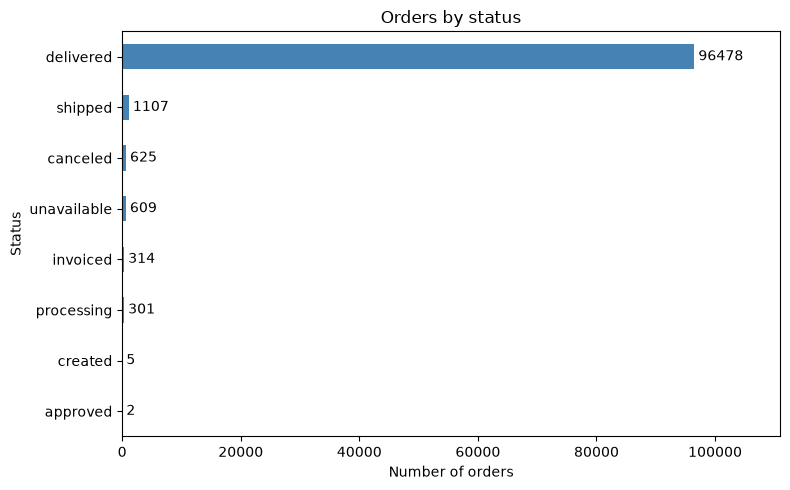

In [6]:
orders_by_status = (orders.groupby("order_status")["order_id"]
    .nunique()
    .sort_values())

ax = orders_by_status.plot.barh(figsize=(8, 5), color="steelblue")

ax.set_title("Orders by status")
ax.set_xlabel("Number of orders")
ax.set_ylabel("Status")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(x=0.15)

plt.tight_layout()
plt.show()

## Baskets and recurring orders

In [7]:
category = "product_category_name"
customer = "customer_unique_id"
purchase_date = "order_purchase_timestamp"

category_records = with_category.drop_duplicates(["order_id", category]).copy()

basket = category_records.groupby("order_id")[category].agg(set)
basket_size = basket.str.len()

history = category_records.dropna(subset=[customer]).copy()

orders_per_customer = history.groupby(customer)["order_id"].nunique()

print("Purchase dates within selected period:", category_records[purchase_date].min(), "a", category_records[purchase_date].max())
print("Orders in period:", len(basket))
print("Orders with two or more categories:", basket_size.ge(2).sum())
print("Perc order:",  f"{(basket_size >= 2).mean():.2%}")
print("Category:", category_records[category].nunique())
print("Orders without a persistent customer:", category_records.loc[category_records[customer].isna(), "order_id"].nunique())
print("Identified customers:", len(orders_per_customer))
print("Customers with two or more orders:", orders_per_customer.ge(2).sum())
print("Perc customer:", f"{(orders_per_customer >= 2).mean():.2%}")

basket_size.value_counts().sort_index().rename("Number of orders").to_frame()

Purchase dates within selected period: 2016-09-15 12:16:38 a 2018-08-29 15:00:37
Orders in period: 95146
Orders with two or more categories: 723
Perc order: 0.76%
Category: 73
Orders without a persistent customer: 0
Identified customers: 92098
Customers with two or more orders: 2742
Perc customer: 2.98%


,Number of orders
product_category_name,
1,94423
2,708
3,15


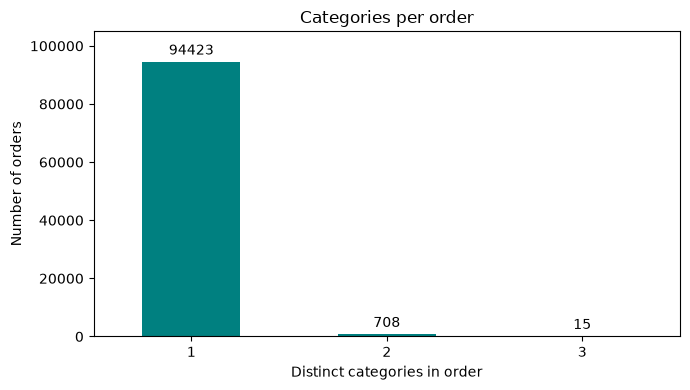

In [8]:
categories_per_order = basket_size.value_counts().sort_index()

ax = categories_per_order.plot.bar(figsize=(7, 4),color="teal")

ax.set_title("Categories per order")
ax.set_xlabel("Distinct categories in order")
ax.set_ylabel("Number of orders")
ax.tick_params(axis="x", rotation=0)
ax.bar_label(ax.containers[0], padding=3)
ax.set_ylim(top=105_000)


plt.tight_layout()
plt.show()

## Train and Test

In [9]:
cutoff_date = pd.Timestamp("2018-05-01")

train = history.loc[history[purchase_date] < cutoff_date].copy()
after_cut = history.loc[history[purchase_date] >= cutoff_date].copy()

known_customers = after_cut[customer].isin(train[customer].unique())

next_order = (after_cut.loc[known_customers, [customer, "order_id", purchase_date]]
    .sort_values([purchase_date, "order_id"])
    .drop_duplicates(customer))

test = after_cut.merge(next_order[[customer, "order_id"]],
    on=[customer, "order_id"],
    validate="many_to_one",)

train_interactions = train[[customer, category]].drop_duplicates()

relevant = test.groupby(customer)[category].agg(set)

out_of_catalog = ~test[category].isin(train_interactions[category])


print("Train orders:", train["order_id"].nunique())
print("Test customers:", len(relevant))
print("Post cutoff customers without history:", after_cut.loc[~known_customers, customer].nunique())
print("Out of atalog test category share:, "f"{(out_of_catalog >= 2).mean():.2%}")

Train orders: 69907
Test customers: 528
Post cutoff customers without history: 24370
Out of atalog test category share:, 0.00%


## Ranked by popularity

In [10]:
train_frequency = (train.groupby(category)["order_id"]
    .nunique()
    .rename("order")
    .reset_index()
    .sort_values(["order", category], ascending=[False, True]))


display(train_frequency.head(10))

,product_category_name,order
13,cama_mesa_banho,6957
32,esporte_lazer,5868
11,beleza_saude,5724
44,informatica_acessorios,5018
54,moveis_decoracao,4851
71,utilidades_domesticas,3776
65,relogios_presentes,3572
69,telefonia,3212
12,brinquedos,3118
26,cool_stuff,3062


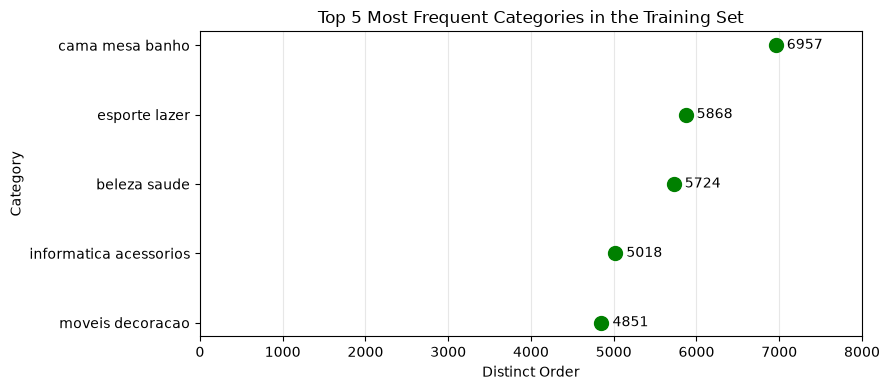

In [11]:
top_5 = (train_frequency.head(5)
       .sort_values("order"))

names = top_5[category].str.replace("_", " ", regex=False)

fig, ax = plt.subplots(figsize=(9, 4))

ax.scatter(top_5["order"], names, color="green", s=100)

for number, names in zip(top_5["order"], names):
    ax.annotate(
        str(number), (number, names), xytext=(8, 0),textcoords = "offset points", va="center")


ax.set_title("Top 5 Most Frequent Categories in the Training Set")
ax.set_xlabel("Distinct Order")
ax.set_ylabel("Category")
ax.set_xlim(0, top_5["order"].max() * 1.15)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)


plt.tight_layout()
plt.show()


In [12]:
categories = train_interactions["product_category_name"].dropna().unique()
print(", ".join(categories))

utilidades_domesticas, pet_shop, papelaria, automotivo, moveis_decoracao, moveis_escritorio, ferramentas_jardim, informatica_acessorios, brinquedos, construcao_ferramentas_construcao, telefonia, cama_mesa_banho, beleza_saude, eletronicos, bebes, cool_stuff, perfumaria, climatizacao, esporte_lazer, livros_interesse_geral, relogios_presentes, alimentos, malas_acessorios, fashion_bolsas_e_acessorios, instrumentos_musicais, market_place, eletrodomesticos, agro_industria_e_comercio, artigos_de_festas, casa_conforto, cds_dvds_musicais, construcao_ferramentas_iluminacao, consoles_games, moveis_quarto, construcao_ferramentas_seguranca, telefonia_fixa, fashion_calcados, casa_construcao, audio, eletrodomesticos_2, eletroportateis, cine_foto, moveis_cozinha_area_de_servico_jantar_e_jardim, industria_comercio_e_negocios, bebidas, artes, fashion_roupa_masculina, construcao_ferramentas_jardim, artigos_de_natal, tablets_impressao_imagem, fashion_esporte, moveis_sala, la_cuisine, flores, alimentos_beb

## Collaborative models and anlysis

##### I chose to keep the functions directly within the notebook in order to consolidate the code,explanations, and results into a single file. 

In [13]:
matrix = pd.crosstab(train_interactions[customer], train_interactions[category])

test_customers = relevant.index
categorys = matrix.columns.to_numpy()
test_histories = matrix.loc[test_customers].to_numpy(dtype=float)
popularity = train_frequency.set_index(category)["order"].reindex(categorys).to_numpy()

def normalize(matrix):
    norms = np.linalg.norm(matrix, axis=1, keepdims=True)
    return matrix / np.where(norms > 0, norms, 1)

def top_categories(score):
    rank = np.lexsort((categorys, -popularity, -score))
    return categorys[rank[:5]].tolist()

# user-user.Excludes the customer themselves from the list of neighbors.
customer_profiles = normalize(matrix.to_numpy(dtype=float))
customer_positions = matrix.index.get_indexer(test_customers)
neighborhood = normalize(test_histories) @ customer_profiles.T
neighborhood[np.arange(len(test_customers)), customer_positions] = 0

per_user = []
for similarities in neighborhood:
    rank = np.argsort(-similarities, kind="stable")[:20]
    score = similarities[rank] @ matrix.to_numpy()[rank]
    per_user.append(top_categories(score))

# Item–item. Each item represents a product category.
category_profiles = normalize(matrix.to_numpy(dtype=float).T)
similarities_items = category_profiles @ category_profiles.T
score_items = (test_histories @ similarities_items) / test_histories.sum(axis=1, keepdims=True)
per_item = [top_categories(score) for score in score_items]



display(matrix.iloc[:5, :8])

product_category_name,agro_industria_e_comercio,alimentos,alimentos_bebidas,artes,artes_e_artesanato,artigos_de_festas,artigos_de_natal,audio
customer_unique_id,,,,,,,,
0000f46a3911fa3c0805444483337064,0,0,0,0,0,0,0,0
0000f6ccb0745a6a4b88665a16c9f078,0,0,0,0,0,0,0,0
0004aac84e0df4da2b147fca70cf8255,0,0,0,0,0,0,0,0
0004bd2a26a76fe21f786e4fbd80607f,0,0,0,0,0,0,0,0
00050ab1314c0e55a6ca13cf7181fecf,0,0,0,0,0,0,0,0


In [14]:
#checking...

exem = matrix.iloc[:5]

purchased_category = exem.columns[
    exem.sum(axis=0) > 0]

display(exem[purchased_category])

product_category_name,ferramentas_jardim,papelaria,telefonia
customer_unique_id,,,
0000f46a3911fa3c0805444483337064,0,1,0
0000f6ccb0745a6a4b88665a16c9f078,0,0,1
0004aac84e0df4da2b147fca70cf8255,0,0,1
0004bd2a26a76fe21f786e4fbd80607f,1,0,0
00050ab1314c0e55a6ca13cf7181fecf,0,0,1


In [15]:
#checking...


print("Customer:", test_customers[0])

print("\nPurchase_Cat_Train:")
print(matrix.columns[test_histories[0] > 0].tolist())

result_exem = pd.DataFrame({
    "User_user": per_user[0],
    "Item–item": per_item[0]
})

result_exem.index = range(1, len(result_exem) + 1)
result_exem.index.name = "Position"

display(result_exem)

Customer: 012452d40dafae4df401bced74cdb490

Purchase_Cat_Train:
['moveis_escritorio']


,User_user,Item–item
Position,,
1,moveis_escritorio,moveis_escritorio
2,cama_mesa_banho,moveis_sala
3,esporte_lazer,moveis_decoracao
4,beleza_saude,cama_mesa_banho
5,informatica_acessorios,eletrodomesticos_2


In [16]:
#checking...

#next purchase (in fiuture)

print("Purchase Categ in test:")
print(sorted(relevant.loc[test_customers[0]]))

Purchase Categ in test:
['beleza_saude']


In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


text_categories= [name.replace("_", " ") for name in categorys]

vectorizer = TfidfVectorizer()
content_vectors = vectorizer.fit_transform(text_categories)

content_profiles = (test_histories @ content_vectors.toarray()) / test_histories.sum(axis=1, keepdims=True)

content_similarities = cosine_similarity(content_profiles, content_vectors)

per_content = [top_categories(score)
    for score in content_similarities]


display(pd.DataFrame({
    "Category": categorys,
    "Text used": text_categories}).head(10))

print("Example of content-based recommendations:", per_content[0])

,Category,Text used
0,agro_industria_e_comercio,agro industria e comercio
1,alimentos,alimentos
2,alimentos_bebidas,alimentos bebidas
3,artes,artes
4,artes_e_artesanato,artes e artesanato
5,artigos_de_festas,artigos de festas
6,artigos_de_natal,artigos de natal
7,audio,audio
8,automotivo,automotivo
9,bebes,bebes


Example of content-based recommendations: ['moveis_escritorio', 'moveis_decoracao', 'moveis_sala', 'moveis_quarto', 'moveis_colchao_e_estofado']


In [18]:
recommendations = {
    "popularity": [top_categories(popularity)] * len(test_customers),
    "user-user": per_user,
    "Item–item": per_item,}

result = []

for method, lists in recommendations.items():
    recalls = []


    for suggestions, actual_categories in zip(lists, relevant):
        hits = len(set(suggestions) & actual_categories)
        recalls.append(hits / len(actual_categories))

    result.append({
        "Method": method,
        "Recall@5": np.mean(recalls)})
    

comparison = pd.DataFrame(result).set_index("Method")
display(comparison.round(4))

,Recall@5
Method,
popularity,0.4441
user-user,0.5312
Item–item,0.3920


In [19]:
# Anonymized example: The first record in the test, following the index order.
print("Categories in history:", ", ".join(matrix.columns[test_histories[0] > 0]))
print("Categories in the test order.:", ", ".join(sorted(relevant.iloc[0])))
for method, lists in recommendations.items():
    print(method, "→", ", ".join(lists[0]))

Categories in history: moveis_escritorio
Categories in the test order.: beleza_saude
popularity → cama_mesa_banho, esporte_lazer, beleza_saude, informatica_acessorios, moveis_decoracao
user-user → moveis_escritorio, cama_mesa_banho, esporte_lazer, beleza_saude, informatica_acessorios
Item–item → moveis_escritorio, moveis_sala, moveis_decoracao, cama_mesa_banho, eletrodomesticos_2


## Apriori e ECLAT


In [20]:
from collections import Counter
from math import ceil
from time import perf_counter
import tracemalloc

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori as apriori_mlxtend
from mlxtend.frequent_patterns import association_rules


def apriori(basket, minimum, maximum):
    encoder = TransactionEncoder()
    matrix_category_records = encoder.fit(basket).transform(basket)
    basket_table = pd.DataFrame(matrix_category_records, columns=encoder.columns_)

    sets = apriori_mlxtend(
        basket_table,
        min_support=minimum / len(basket),
        use_colnames=True,
        max_len=maximum
    )

    frequent = {}

    for _, line in sets.iterrows():

        group = tuple(sorted(line["itemsets"]))
        frequent[group] = int(round(line["support"] * len(basket)))

    return frequent


def eclat(basket, minimum, maximum):
    orders_by_item = {}
    for indice, basket in enumerate(basket):
        for item in basket:
            orders_by_item.setdefault(item, set()).add(indice)
        candidates = sorted(
        (item, ids) for item, ids in orders_by_item.items() if len(ids) >= minimum
    )
    frequent = {}

    def extend(prefix, candidates):
        for position, (item, ids) in enumerate(candidates):
            group = prefix + (item,)
            frequent[group] = len(ids)
            if len(group) < maximum:
                next = []
                for other, other_ids in candidates[position + 1:]:
                    common = ids & other_ids
                    if len(common) >= minimum:
                        next.append((other, common))
                extend(group, next)

    extend((), candidates)
    return frequent

In [21]:
basket_model = basket.tolist()
min_support = 0.0002
min_confidence = 0.01
max_items = 3
minimum = ceil(min_support * len(basket_model))

def measure(algorithm):
    runtime = []
    for attempt in range(3):
        start = perf_counter()
        result = algorithm(basket_model, minimum, max_items)
        runtime.append((perf_counter() - start) * 1000)


    
    tracemalloc.start()
    try:
        algorithm(basket_model, minimum, max_items)
        _, peak = tracemalloc.get_traced_memory()
    finally:
        tracemalloc.stop()
    return result, np.median(runtime), peak / (1024 ** 2)

group_apriori, runtime_apriori, memory_apriori = measure(apriori)
group_eclat, runtime_eclat, memory_eclat = measure(eclat)
assert group_apriori == group_eclat, "Apriori and Eclat should return the same frequent itemsets."
print("Min support order:", minimum)
print("Size Sets:", dict(sorted(Counter(map(len, group_apriori)).items())))

perfomance = pd.DataFrame(
    [
        ("Apriori", len(group_apriori), runtime_apriori, memory_apriori),
        ("ECLAT", len(group_eclat), runtime_eclat, memory_eclat),
    ],
    columns=["Algorithm", "Set Frequent", "Median runtime (mr)", "Python peak (MiB)"],
).set_index("Algorithm")
perfomance.round(2)

Min support order: 20
Size Sets: {1: 67, 2: 5}


,Set Frequent,Median runtime (mr),Python peak (MiB)
Algorithm,,,
Apriori,72,2812.62,609.40
ECLAT,72,2168.27,8.28


In [22]:
def generate_rule(group, total, min_confidence):
    columns = ["Antecedent", "Consequent", "Order ", "Support", "Confidence", "Lift"]

    # sets isolados não geram rules.
    if not any(len(group) >= 2 for group in group):
        return pd.DataFrame(columns=columns)

    sets = pd.DataFrame({
        "support": [count / total for count in group.values()],
        "itemsets": [frozenset(group) for group in group]
    })

    rules_mlxtend = association_rules(
        sets,
        num_itemsets=total,
        metric="confidence",
        min_threshold=min_confidence,
        return_metrics=["support", "confidence", "lift"]
    )

    result = pd.DataFrame({
        "Antecedent": rules_mlxtend["antecedents"].map(
            lambda group: ", ".join(sorted(group))
        ),
        "Consequent": rules_mlxtend["consequents"].map(
            lambda group: ", ".join(sorted(group))
        ),
        "Order": (rules_mlxtend["support"] * total).round().astype(int),
        "Support": rules_mlxtend["support"],
        "Confidence": rules_mlxtend["confidence"],
        "Lift": rules_mlxtend["lift"]
    })

    return result.sort_values(
        ["Lift", "Order", "Antecedent", "Consequent"],
        ascending=[False, False, True, True],
        ignore_index=True
    )


rules = generate_rule(group_apriori, len(basket_model), min_confidence)
rules_eclat = generate_rule(group_eclat, len(basket_model), min_confidence)

pd.testing.assert_frame_equal(rules, rules_eclat)
display(rules.round(5))

,Antecedent,Consequent,Order,Support,Confidence,Lift
0,casa_conforto,cama_mesa_banho,43,0.00045,0.10969,1.12564
1,moveis_decoracao,cama_mesa_banho,70,0.00074,0.01110,0.11389


In [23]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori as apriori_mlxtend
from mlxtend.frequent_patterns import association_rules


Visualization

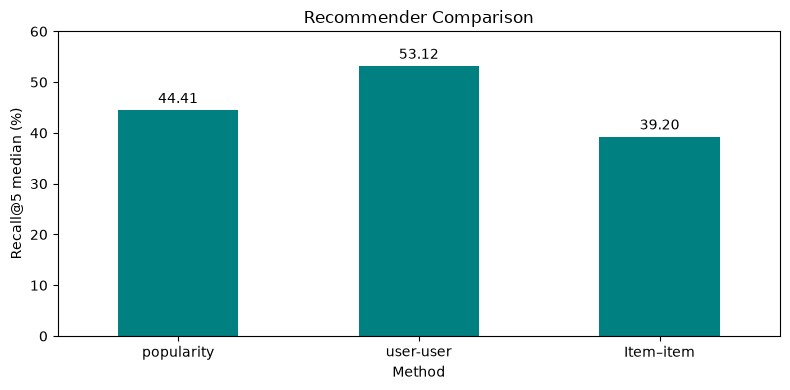

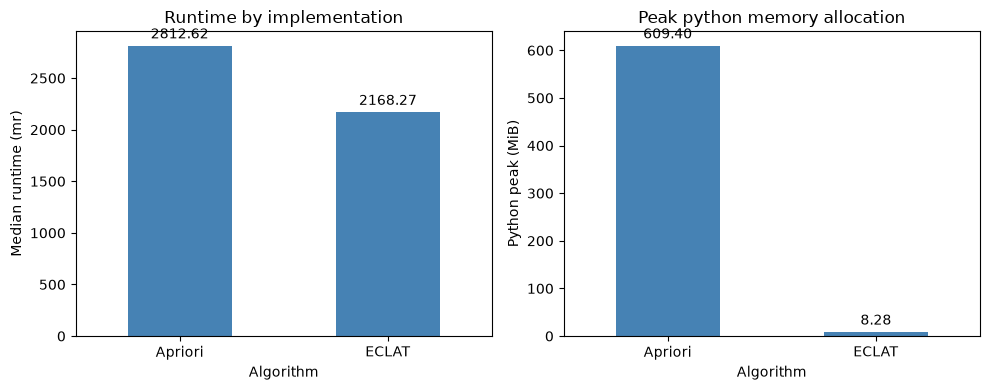

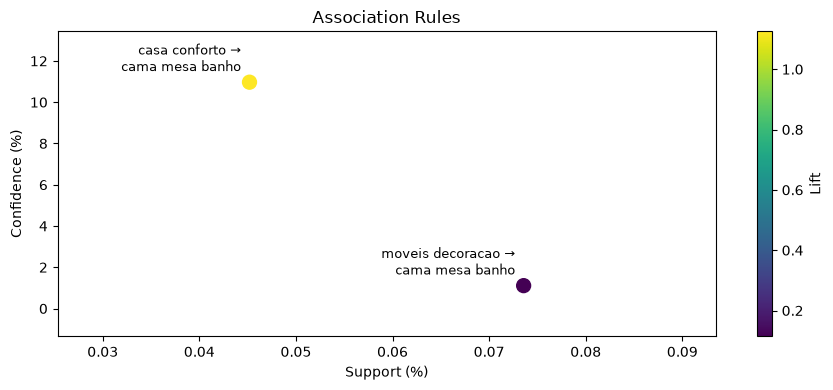

In [98]:
import matplotlib.pyplot as plt

ax = (comparison["Recall@5"] * 100).plot.bar(figsize=(8, 4), color="teal")
ax.set_title("Recommender Comparison")
ax.set_xlabel("Method")
ax.set_ylabel("Recall@5 median (%)")
ax.tick_params(axis="x", rotation=0)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
ax.set_ylim(0, 60)

plt.tight_layout()
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(10, 4))

for axes, columns, title in zip(
    axes,
    ["Median runtime (mr)", "Python peak (MiB)"],
    ["Runtime by implementation", "Peak python memory allocation"]):
    perfomance[columns].plot.bar(ax=axes, color="steelblue") 
    axes.set_title(title)
    axes.set_xlabel("Algorithm")
    axes.set_ylabel(columns)
    axes.tick_params(axis="x", rotation=0)
    axes.bar_label(axes.containers[0], fmt="%.2f", padding=3)



plt.tight_layout()
plt.show()

if not rules.empty:
    figure, axes = plt.subplots(figsize=(9, 4))
    score = axes.scatter(
        rules["Support"] * 100,
        rules["Confidence"] * 100,
        c=rules["Lift"], cmap="viridis", s=100)
    for _, rule in rules.iterrows():
        name = rule["Antecedent"] + " →\n" + rule["Consequent"]
        axes.annotate(name.replace("_", " "),(rule["Support"] * 100, rule["Confidence"] * 100),
            xytext=(-6, 8), textcoords="offset points", fontsize=9, ha="right")
    axes.set_title("Association Rules")
    axes.set_xlabel("Support (%)")
    axes.set_ylabel("Confidence (%)")
    axes.margins(x=0.7, y=0.25)
    figure.colorbar(score, ax=axes, label="Lift")
    plt.tight_layout()
    plt.show()
else:
    print("No association rules met the specified thresholds..")

In [83]:
import json

dash_order = category_records.groupby("order_id").agg(
    date=(purchase_date, "first"),
    state=("customer_state", "first"),
    customer=(customer, "first"),
    categories=(category, list),)

display(dash_order.head())

,date,state,customer,categories
order_id,,,,
00010242fe8c5a6d1ba2dd792cb16214,2017-09-13 08:59:02,RJ,871766c5855e863f6eccc05f988b23cb,[cool_stuff]
00018f77f2f0320c557190d7a144bdd3,2017-04-26 10:53:06,SP,eb28e67c4c0b83846050ddfb8a35d051,[pet_shop]
000229ec398224ef6ca0657da4fc703e,2018-01-14 14:33:31,MG,3818d81c6709e39d06b2738a8d3a2474,[moveis_decoracao]
00024acbcdf0a6daa1e931b038114c75,2018-08-08 10:00:35,SP,af861d436cfc08b2c2ddefd0ba074622,[perfumaria]
00042b26cf59d7ce69dfabb4e55b4fd9,2017-02-04 13:57:51,SP,64b576fb70d441e8f1b2d7d446e483c5,[ferramentas_jardim]


In [95]:
customer_cod = pd.factorize(dash_order["customer"])[0]

names_categorys = sorted(category_records[category].unique())

category_cod = {name: i for i, name in enumerate(names_categorys)}

dash_rows = []

for month, state, code, names in zip(
    dash_order["date"].dt.strftime("%Y-%m"),
    dash_order["state"].fillna(""),
    customer_cod, 
    dash_order["categories"],):

    
    dash_rows.append([month,
                      state,
                      int(code), 
                      [category_cod[name] for name in names]])

print("Prepared Orders:", len(dash_order))
print("Exemplo:", dash_order.iloc[0])

Prepared Orders: 95146
Exemplo: date                       2017-09-13 08:59:02
state                                       RJ
customer      871766c5855e863f6eccc05f988b23cb
categories                        [cool_stuff]
Name: 00010242fe8c5a6d1ba2dd792cb16214, dtype: object


In [97]:
dash_data = {
    "orders": dash_rows,
    "categorys": names_categorys,
    "model": comparison["Recall@5"].reset_index().values.tolist(),
    "algorithm": perfomance.reset_index().values.tolist(),
    "rules": rules.values.tolist(),}

content = json.dumps(dash_data, ensure_ascii=False, separators=(",", ":"))
content = content.replace

In [99]:
model_html = r'''<!doctype html>
<html lang="pt-BR">
<head>
    <meta charset="utf-8">
    <meta name="viewport" content="width=device-width, initial-scale=1">

    <title>Purchase Olist</title>

    <style>
        * {
            box-sizing: border-box;
        }

        body {
            margin: 0;
            background: #f5f7fa;
            color: #182539;
            font: 16px/1.5 system-ui, sans-serif;
        }

        main {
            max-width: 1120px;
            margin: auto;
            padding: 32px 24px 44px;
        }

        h1 {
            font-size: clamp(2rem, 5vw, 3.25rem);
            line-height: 1.12;
            margin: 6px 0 8px;
        }

        h2 {
            font-size: 1.28rem;
            margin: 0 0 8px;
        }

        p {
            margin: 0 0 12px;
        }

        .muted {
            color: #475569;
        }

        .filters,
        .kpis,
        .grid {
            display: grid;
            gap: 14px;
        }

        .filters {
            grid-template-columns: repeat(2, minmax(0, 210px));
            margin: 20px 0 14px;
        }

        .kpis {
            grid-template-columns: repeat(3, 1fr);
            margin-bottom: 14px;
        }

        .grid {
            grid-template-columns: repeat(2, minmax(0, 1fr));
            margin-bottom: 14px;
        }

        .card {
            background: white;
            border: 1px solid #d6dfe8;
            border-radius: 12px;
            padding: 18px;
        }

        .kpis strong {
            display: block;
            font-size: 1.8rem;
            line-height: 1.2;
        }

        label {
            display: block;
            font-weight: 650;
        }

        select {
            width: 100%;
            margin-top: 4px;
            padding: 7px 9px;
            border: 1px solid #64748b;
            border-radius: 6px;
            background: white;
            color: inherit;
            font: inherit;
        }

        :focus-visible {
            outline: 3px solid #075985;
            outline-offset: 3px;
        }

        .bars {
            list-style: none;
            padding: 0;
            margin: 12px 0 0;
        }

        .bar {
            margin: 9px 0;
        }

        .row {
            display: flex;
            gap: 10px;
            justify-content: space-between;
            align-items: baseline;
        }

        .track {
            height: 8px;
            background: #e7edf4;
            border-radius: 5px;
            margin-top: 3px;
        }

        .fill {
            height: 100%;
            background: #0c6274;
            border-radius: 5px;
        }

        .table {
            overflow-x: auto;
        }

        table {
            border-collapse: collapse;
            width: 100%;
            margin: 8px 0;
        }

        th,
        td {
            padding: 8px;
            text-align: left;
            border-bottom: 1px solid #d6dfe8;
        }

        th {
            background: #eef3f8;
        }

        #rules {
            margin: 14px 0;
        }

        #regra {
            max-width: 300px;
        }

        .plot {
            display: block;
            width: 100%;
            max-width: 560px;
            height: auto;
            margin: 12px 0;
        }

        footer {
            font-size: 0.9rem;
            margin-top: 18px;
        }

        a {
            color: #075985;
        }

        @media (max-width: 650px) {
            main {
                padding: 22px 14px;
            }

            .grid {
                grid-template-columns: 1fr;
            }

            .kpis {
                gap: 6px;
            }

            .kpis .card {
                padding: 8px;
            }

            .kpis strong {
                font-size: 1.35rem;
            }

            .card {
                padding: 14px;
            }
        }
    </style>
</head>

<body>
<main>

    <header>
        <h1>Purchase Olist</h1>

        <p class="muted">
            Delivered Orders with Identified Categories ·
            September 2016 to August 2018.
            The first and last months are only partially covered.
        </p>
    </header>

    <!-- Overview Filters -->
    <div class="filters">
        <label for="month">
            Purchase Month
            <select id="month"></select>
        </label>

        <label for="state">
            Customer State
            <select id="state"></select>
        </label>
    </div>

    <!-- Key Metrics -->
    <section
        class="kpis"
        aria-label="Filtered Summary"
        aria-live="polite"
    >
        <div class="card">
            Orders
            <strong id="orders">—</strong>
        </div>

        <div class="card">
            Customers
            <strong id="customers">—</strong>
        </div>

        <div class="card">
            Categories
            <strong id="categories">—</strong>
        </div>
    </section>

    <!-- Bar Charts -->
    <div class="grid">
        <section class="card">
            <h2>Most Purchased Categories</h2>
            <p class="muted">Distinct Orders by Category.</p>
            <ul id="ranking" class="bars"></ul>
        </section>

        <section class="card">
            <h2>Basket Size</h2>
            <p id="multiple" class="muted"></p>
            <ul id="Basket" class="bars"></ul>
        </section>

        <section class="card">
            <h2>Purchase by Customers</h2>
            <p id="repeat" class="muted"></p>
            <ul id="history" class="bars"></ul>
        </section>

        <section class="card">
            <h2>Recommendation Hits</h2>

            <p class="muted">
                Mean Recall@5 Test Orders
                The evaluation uses the same fixed set of customers.
                Across all four methods. It measures the share of categories
                purchased that appeared among the top five recommendations.
            </p>

            <ul id="models" class="bars"></ul>
        </section>
    </div>

    <!-- Association Rules -->
    <section class="card" id="rules">
        <h2>Categories Purchased Together</h2>

        <p class="muted">
            Rules are calculated using all orders that match the selected filters,
            with a minimum support of 0.02% and a minimum confidence of 1%.
        </p>

        <label for="rule">
            Category in the Rule
            <select id="rule"></select>
        </label>

        <canvas
            id="chart"
            class="plot"
            width="560"
            height="220"
            role="img"
            aria-label="Support vs. Confidence.
                        The values are also shown in the table."
        ></canvas>

        <div class="table">
            <table>
                <thead>
                    <tr>
                        <th>If any</th>
                        <th>Is also shown</th>
                        <th>Orders</th>
                        <th>Support</th>
                        <th>confidence</th>
                        <th>Lift</th>
                    </tr>
                </thead>

                <tbody id="rules"></tbody>
            </table>
        </div>

        <p class="muted">
            Support is the share of all orders that contain both categories.
            Confidence is the parcel of orders containing the first category
            that also contain the second category. A lift greater than 1 indicates that the second
            category is more common in those orders than in orders overall.
        </p>
    </section>

    <!-- Algorithm Performance -->
    <section class="card">
        <h2>Market Basket Analysis Performance</h2>

        <p class="muted">
            Apriori from mlxtend and ECLAT in Python.
            Median runtime across three runs, including data conversions
            internal conversions, and peak memory tracked by Python.
        </p>

        <div class="table">
            <table>
                <thead>
                    <tr>
                        <th>Algorithm</th>
                        <th>Sets</th>
                        <th>Time (ms)</th>
                        <th>Peak (MiB)</th>
                    </tr>
                </thead>

                <tbody id="Algorithms"></tbody>
            </table>
        </div>
    </section>

    <footer>
        Fonte:
        <a href="https://www.kaggle.com/olistbr/brazilian-ecommerce">
            Brazilian E-Commerce Public Dataset by Olist
        </a>
        · CC BY-NC-SA 4.0.
        Data filtered and grouped for this analysis.
    </footer>

    <!-- The data will be inserted by the fifth cell. -->
    <script type="application/json" id="datas">__DATAS__</script>

    <script>
        // Ler os datas prepared in Python.
        const data = JSON.parse(
            document.getElementById("datas").textContent
        );

        const el = id => document.getElementById(id);

        // Format numbers and percentages.
        const integer = new Intl.NumberFormat("pt-BR");

        const decimal = new Intl.NumberFormat(
            "pt-BR",
            { maximumFractionDigits: 2 }
        );

        const percent = (value, digits = 1) =>
            new Intl.NumberFormat(
                "pt-BR",
                {
                    style: "percent",
                    minimumFractionDigits: digits,
                    maximumFractionDigits: digits
                }
            ).format(value);

        const label = value => value.replaceAll("_", " ");

        // Populate the filter options.
        function options(id, values, first) {
            el(id).add(new Option(first, ""));

            values.forEach(value => {
                el(id).add(new Option(label(value), value));
            });
        }

        options(
            "month",
            Array.from(
                new Set(data.Orders.map(row => row[0]))
            ).sort(),
            "All Months"
        );

        options(
            "state",
            Array.from(
                new Set(data.Orders.map(row => row[1]))
            ).filter(Boolean).sort(),
            "All states"
        );

        const CategoriesRules = Array.from(
            new Set(
                data.rules.flatMap(row => [
                    ...row[0].split(", "),
                    ...row[1].split(", ")
                ])
            )
        ).sort();

        options(
            "rule",
            CategoriesRules,
            "All Categories"
        );

        // Increment the occurrence count.
        function addCount(map, key) {
            map.set(key, (map.get(key) || 0) + 1);
        }

        // Create a bar chart with value labels.
        function bars(
            id,
            values,
            format = integer.format,
            cap = null
        ) {
            const area = el(id);
            area.replaceChildren();

            if (!values.some(([, value]) => value)) {
                const item = document.createElement("li");
                item.textContent = "No dates match the selected filter..";
                area.append(item);
                return;
            }

            const max = cap || Math.max(
                ...values.map(row => row[1])
            );

            values.forEach(([name, value]) => {
                const item = document.createElement("li");
                item.className = "bar";

                const line = document.createElement("div");
                line.className = "row";

                const text = document.createElement("span");
                text.textContent = name;

                const number = document.createElement("strong");
                number.textContent = format(value);

                const track = document.createElement("div");
                track.className = "track";
                track.setAttribute("aria-hidden", "true");

                const fill = document.createElement("div");
                fill.className = "fill";
                fill.style.width = (100 * value / max) + "%";

                line.append(text, number);
                track.append(fill);
                item.append(line, track);
                area.append(item);
            });
        }

        // Update the key metrics and descriptive charts.
        function renderSummary() {
            const customer = new Map();
            const category = new Map();
            const size = [0, 0, 0];

            let total = 0;

            const selectedMonth = el("month").value;
            const selectedState = el("state").value;

            for (
                const [month, state, id, cats]
                of data.Orders
            ) {
                if (
                    (selectedMonth && month !== selectedMonth) ||
                    (selectedState && state !== selectedState)
                ) {
                    continue;
                }

                total++;

                if (id >= 0) {
                    addCount(customer, id);
                }

                cats.forEach(cat => addCount(category, cat));

                // Group orders into three bins: one category, two categories, and three or more categories.
                size[Math.min(cats.length, 3) - 1]++;
            }

            const frequency = [0, 0, 0];

            customer.forEach(number => {
                frequency[Math.min(number, 3) - 1]++;
            });

            el("orders").textContent = integer.format(total);

            el("customers").textContent = integer.format(
                customer.size
            );

            el("categories").textContent = integer.format(
                category.size
            );

            if (total > 0) {
                el("multiple").textContent =
                    percent((size[1] + size[2]) / total, 2) +
                    " of orders contain two or more categories.";
            } else {
                el("multiple").textContent =
                    "No orders match the selected filter..";
            }

            if (customer.size > 0) {
                el("repeat").textContent =
                    percent(
                        (frequency[1] + frequency[2]) /
                        customer.size,
                        2
                    ) +
                    " customers placed two or more orders." +
                    "within.";
            } else {
                el("repeat").textContent =
                    "No customers match the selected filter.";
            }

            const ranking = Array.from(category)
                .sort(
                    (a, b) =>
                        b[1] - a[1] || a[0] - b[0]
                )
                .slice(0, 8)
                .map(([code, count]) => [
                    label(data.Categories[code]),
                    count
                ]);

            bars("ranking", ranking);

            const nomonthBasket = [
                "1 category",
                "2 Categories",
                "3 or more"
            ];

            bars(
                "Basket",
                size.map((count, index) => [
                    nomonthBasket[index],
                    count
                ])
            );

            const nomonthFrequencia = [
                "1 order",
                "2 Orders",
                "3 or more"
            ];

            bars(
                "history",
                frequency.map((count, index) => [
                    frequencyNames[index],
                    count
                ])
            );
        }

        // Populate a table.
        function rows(id, values) {
            const body = el(id);
            body.replaceChildren();

            for (const line of values) {
                const row = body.insertRow();

                line.forEach(value => {
                    row.insertCell().textContent = value;
                });
            }
        }

        //Update the association rules table and chart.
        function renderRules() {
            const current = el("rule").value;

            const filtered = data.rules.filter(row => {
                const Categories = [
                    ...row[0].split(", "),
                    ...row[1].split(", ")
                ];

                return !current || Categories.includes(current);
            });

            rows(
                "rules",
                filtered.map(row => [
                    label(row[0]),
                    label(row[1]),
                    integer.format(row[2]),
                    percent(row[3], 3),
                    percent(row[4], 2),
                    decimal.format(row[5])
                ])
            );

            const canvas = el("chart");
            const context = canvas.getContext("2d");

            const left = 68;
            const right = 520;
            const top = 18;
            const bottom = 170;

            const xmax = Math.max(
                0.001,
                ...data.rules.map(row => row[3])
            );

            const ymax = Math.max(
                0.12,
                ...data.rules.map(row => row[4])
            );

            context.clearRect(
                0,
                0,
                canvas.width,
                canvas.height
            );

            context.font = "13px system-ui";
            context.fillStyle = "#182539";
            context.strokeStyle = "#d6dfe8";

            for (let index = 0; index <= 4; index++) {
                const x = left + index * (right - left) / 4;
                const y = bottom - index * (bottom - top) / 4;

                context.beginPath();
                context.moveTo(left, y);
                context.lineTo(right, y);
                context.stroke();

                context.fillText(
                    percent(index * ymax / 4, 0),
                    22,
                    y + 4
                );

                context.fillText(
                    percent(index * xmax / 4, 3),
                    x - 18,
                    bottom + 17
                );
            }

            context.fillText("Support", 264, 212);

            context.save();
            context.translate(12, 122);
            context.rotate(-Math.PI / 2);
            context.fillText("confidence", 0, 0);
            context.restore();

            for (const rule of filtered) {
                const x =
                    left +
                    (right - left) * rule[3] / xmax;

                const y =
                    bottom -
                    (bottom - top) * rule[4] / ymax;

                context.fillStyle =
                    rule[5] > 1 ? "#0c6274" : "#7b3a17";

                context.beginPath();
                context.arc(x, y, 6, 0, 2 * Math.PI);
                context.fill();

                context.fillStyle = "#182539";

                context.fillText(
                    "Lift " + decimal.format(rule[5]),
                    x + 9,
                    y + 4
                );
            }
        }

        // Update the dashboard when a filter changes.
        for (const id of ["month", "state"]) {
            el(id).addEventListener(
                "change",
                renderSummary
            );
        }

        el("rule").addEventListener(
            "change",
            renderRules
        );

        // Display the fixed model results and Algorithms.
        bars("models", data.models, percent, 1);

        rows(
            "Algorithms",
            data.Algorithms.map(row => [
                row[0],
                integer.format(row[1]),
                decimal.format(row[2]),
                decimal.format(row[3])
            ])
        );

        // Load the initial view.
        renderSummary();
        renderRules();
    </script>

</main>
</body>
</html>'''

# Reference


https://matplotlib.org/stable/gallery/lines_bars_and_markers/barchart.html